In [1]:
import pandas as pd
import json, os
import hysteresis as hys
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error, r2_score

In [2]:
id_list_json = json.load(open('./Data/Hysteresis/id_list_big.json'))
label = pd.read_csv('./Data/Hysteresis/info_w_mander_big.csv')

In [3]:
def draw_results(drift, simulated_force, pred_force, gt_force, exp, failure_type, mode, hys_exp):
    # Dark mode
    fig = plt.figure(figsize=(4, 4))
    if simulated_force is not None:
        plt.plot(drift, simulated_force, label="Simulated", linestyle="dotted", color="tab:gray", alpha=0.7)
    plt.plot(drift, gt_force, label="Experiment", color="tab:blue", alpha=0.7)
    plt.plot(drift, pred_force, label="Predicted", linestyle="--", color="tab:red", alpha=0.7)
    
    plt.xlabel("Drift (%)")
    plt.ylabel("Force (kN)")
    plt.legend()
    plt.title(f"Specimen {exp}")
    save_path = os.path.join("./temp", hys_exp, failure_type, mode)
    if not os.path.exists(save_path):
        os.makedirs(save_path, exist_ok=True)
    plt.savefig(os.path.join(save_path, f"{exp}.svg"), transparent=False, bbox_inches="tight")
    plt.close("all")

### Different Failure Mode

In [8]:
exp_list = [
    ("Simulation", "./results/HystereticPrediction/HystereticGRU/2024-06-12_18-13-47/csv"),
    ("Exp1", "./results/HystereticPrediction/HystereticGRU/2024-06-12_18-12-54/csv"),
    ("Exp2", "./results/HystereticPrediction/HystereticGRU/2024-06-12_18-12-05/csv"),
    ("Exp3", "./results/HystereticPrediction/HystereticGRU/2024-06-13_16-28-18/csv"),
    ("Exp4", "./results/HystereticPrediction/HystereticGRU/2024-06-13_16-28-08/csv"),
    ("Exp5", "./results/HystereticPrediction/HystereticGRU/2024-06-12_18-13-47/csv"),
    ("LSTM_Exp1", "./results/HystereticPrediction/HystereticLSTM/2024-10-21_21-44-17/csv"),
    ("LSTM_Exp5", "./results/HystereticPrediction/HystereticLSTM/2024-10-21_21-45-24/csv")
   
]

result_list = {"hys_exp":[], "mode":[], "failure_type":[], "mae":[], "mse": [], "rmse": [], "nrmse": [], "r2": [],
               "mae_peak": [], "mse_peak": [], "rmse_peak": [], "nrmse_peak": [], "r2_peak": []}
mode_list = ["val"]


#  Prediction  
for hys_exp, path in exp_list:
    for failure_type in ["Flexure", "Flexure-Shear", "Shear"]:
        for mode in mode_list:
            label_filter = label[label["id"].isin(id_list_json[mode]) & (label["failureType"] == failure_type)]
            force_gt = []
            force_pred = []
            
            force_peak_gt = []
            force_peak_pred = []
            
            nrmse_list = []
            nrmse_peak_list = []
            for id in label_filter['id']:
                mode = "train" if id in id_list_json["train"] else "val"
                df = pd.read_csv(f"{path}/{mode}/{id}.csv")
                drift = df['Drift'].values
                test_force = df['Test'].values
                if hys_exp == "Simulation":
                    predicted_force = df['Simulated'].values
                else:
                    predicted_force = df['Predicted'].values    
                
                hysLoop_test = hys.Hysteresis(np.column_stack([drift, test_force]))
                reversalIndex = hysLoop_test.reversalIndexes

                force_gt.append(test_force)
                force_pred.append(predicted_force)
                force_peak_gt.append(test_force[reversalIndex])
                force_peak_pred.append(predicted_force[reversalIndex])
                
                nrmse = np.sqrt(mean_squared_error(test_force, predicted_force)) / (np.max(test_force) - np.min(test_force))
                nrmse_peak = np.sqrt(mean_squared_error(test_force[reversalIndex], predicted_force[reversalIndex])) / (np.max(test_force) - np.min(test_force))
                
                nrmse_list.append(nrmse)
                nrmse_peak_list.append(nrmse_peak)

            force_gt = np.concatenate(force_gt)
            force_pred = np.concatenate(force_pred)
            force_peak_gt = np.concatenate(force_peak_gt)
            force_peak_pred = np.concatenate(force_peak_pred)
            
            # Calculate metrics
            mae = mean_absolute_error(force_gt, force_pred)
            mse = mean_squared_error(force_gt, force_pred)
            rmse = root_mean_squared_error(force_gt, force_pred)
            nrmse = np.mean(nrmse_list)
            r2 = r2_score(force_gt, force_pred)
            
            mae_peak = mean_absolute_error(force_peak_gt, force_peak_pred)
            mse_peak = mean_squared_error(force_peak_gt, force_peak_pred)
            rmse_peak = root_mean_squared_error(force_peak_gt, force_peak_pred)
            nrmse_peak = np.mean(nrmse_peak_list)
            r2_peak = r2_score(force_peak_gt, force_peak_pred)
                
            for k in result_list.keys():
                result_list[k].append(eval(k))
            
            print(f"{hys_exp} - Failure Type: {failure_type} - Mode: {mode}")
            print(f"MAE Pred: {mae:.4f} - MSE Pred: {mse:.4f} - RMSE Pred: {rmse:.4f} - NRMSE Pred: {nrmse:.4f} - R2 Pred: {r2:.4f}")
            print(f"MAE Peak Pred: {mae_peak:.4f} - MSE Peak Pred: {mse_peak:.4f} - RMSE Peak Pred: {rmse_peak:.4f} - NRMSE Peak Pred: {nrmse_peak:.4f} - R2 Peak Pred: {r2_peak:.4f}")
            print("====================================================================================================")



Simulation - Failure Type: Flexure - Mode: val
MAE Pred: 73.3323 - MSE Pred: 12060.3963 - RMSE Pred: 109.8198 - NRMSE Pred: 0.1122 - R2 Pred: 0.7692
MAE Peak Pred: 80.0495 - MSE Peak Pred: 16799.1483 - RMSE Peak Pred: 129.6115 - NRMSE Peak Pred: 0.1151 - R2 Peak Pred: 0.8713
Simulation - Failure Type: Flexure-Shear - Mode: val
MAE Pred: 34.6464 - MSE Pred: 1699.9700 - RMSE Pred: 41.2307 - NRMSE Pred: 0.1497 - R2 Pred: 0.6952
MAE Peak Pred: 38.8616 - MSE Peak Pred: 2253.8957 - RMSE Peak Pred: 47.4752 - NRMSE Peak Pred: 0.1474 - R2 Peak Pred: 0.8380
Simulation - Failure Type: Shear - Mode: val
MAE Pred: 159.7115 - MSE Pred: 55861.7618 - RMSE Pred: 236.3509 - NRMSE Pred: 0.3088 - R2 Pred: -3.3468
MAE Peak Pred: 224.4985 - MSE Peak Pred: 108734.4097 - RMSE Peak Pred: 329.7490 - NRMSE Peak Pred: 0.4021 - R2 Peak Pred: -2.3131
Exp1 - Failure Type: Flexure - Mode: val
MAE Pred: 39.4267 - MSE Pred: 8098.7294 - RMSE Pred: 89.9929 - NRMSE Pred: 0.0516 - R2 Pred: 0.8450
MAE Peak Pred: 69.6518 - M

In [9]:
df = pd.DataFrame(result_list)
df.to_csv("./HysGRU_failure.csv", index=False)

### Total

In [9]:
exp_list = [
    ("Simulation", "./results/HystereticPrediction/HystereticGRU/2024-06-12_18-13-47/csv"),
    ("Exp1", "./results/HystereticPrediction/HystereticGRU/2024-06-12_18-12-54/csv"),
    ("Exp2", "./results/HystereticPrediction/HystereticGRU/2024-06-12_18-12-05/csv"),
    ("Exp3", "./results/HystereticPrediction/HystereticGRU/2024-06-13_16-28-18/csv"),
    ("Exp4", "./results/HystereticPrediction/HystereticGRU/2024-06-13_16-28-08/csv"),
    ("Exp5", "./results/HystereticPrediction/HystereticGRU/2024-06-12_18-13-47/csv"),
    ("LSTM_Exp1", "./results/HystereticPrediction/HystereticLSTM/2024-10-21_21-44-17/csv"),
    ("LSTM_Exp5", "./results/HystereticPrediction/HystereticLSTM/2024-10-21_21-45-24/csv")
   
]
result_list = {"hys_exp":[], "mae":[], "mse": [], "rmse": [], "nrmse": [], "r2": [],
               "mae_peak": [], "mse_peak": [], "rmse_peak": [], "nrmse_peak": [], "r2_peak": []}
mode_list = ["val"]


for hys_exp, path in exp_list:
    for mode in mode_list:
        label_filter = label[label["id"].isin(id_list_json[mode])]
        force_gt = []
        force_pred = []
        
        force_peak_gt = []
        force_peak_pred = []
        
        nrmse_list = []
        nrmse_peak_list = []
        for id in label_filter['id']:
            mode = "train" if id in id_list_json["train"] else "val"
            df = pd.read_csv(f"{path}/{mode}/{id}.csv")
            drift = df['Drift'].values
            test_force = df['Test'].values
            if hys_exp == "Simulation":
                predicted_force = df['Simulated'].values
            else:
                predicted_force = df['Predicted'].values
            
            hysLoop_test = hys.Hysteresis(np.column_stack([drift, test_force]))
            reversalIndex = hysLoop_test.reversalIndexes

            force_gt.append(test_force)
            force_pred.append(predicted_force)
            force_peak_gt.append(test_force[reversalIndex])
            force_peak_pred.append(predicted_force[reversalIndex])
            
            nrmse = np.sqrt(mean_squared_error(test_force, predicted_force)) / (np.max(test_force) - np.min(test_force))
            nrmse_peak = np.sqrt(mean_squared_error(test_force[reversalIndex], predicted_force[reversalIndex])) / (np.max(test_force) - np.min(test_force))
            
            nrmse_list.append(nrmse)
            nrmse_peak_list.append(nrmse_peak)

        force_gt = np.concatenate(force_gt)
        force_pred = np.concatenate(force_pred)
        force_peak_gt = np.concatenate(force_peak_gt)
        force_peak_pred = np.concatenate(force_peak_pred)
        
        # Calculate metrics
        mae = mean_absolute_error(force_gt, force_pred)
        mse = mean_squared_error(force_gt, force_pred)
        rmse = root_mean_squared_error(force_gt, force_pred)
        nrmse = np.mean(nrmse_list)
        r2 = r2_score(force_gt, force_pred)
        
        mae_peak = mean_absolute_error(force_peak_gt, force_peak_pred)
        mse_peak = mean_squared_error(force_peak_gt, force_peak_pred)
        rmse_peak = root_mean_squared_error(force_peak_gt, force_peak_pred)
        nrmse_peak = np.mean(nrmse_peak_list)
        r2_peak = r2_score(force_peak_gt, force_peak_pred)
            
        for k in result_list.keys():
            result_list[k].append(eval(k))
        
        print(f"{hys_exp} - Failure Type: All - Mode: {mode}")
        print(f"MAE Pred: {mae:.4f} - MSE Pred: {mse:.4f} - RMSE Pred: {rmse:.4f} - NRMSE Pred: {nrmse:.4f} - R2 Pred: {r2:.4f}")
        print(f"MAE Peak Pred: {mae_peak:.4f} - MSE Peak Pred: {mse_peak:.4f} - RMSE Peak Pred: {rmse_peak:.4f} - NRMSE Peak Pred: {nrmse_peak:.4f} - R2 Peak Pred: {r2_peak:.4f}")
        print("====================================================================================================")


Simulation - Failure Type: All - Mode: val
MAE Pred: 81.0459 - MSE Pred: 17017.1887 - RMSE Pred: 130.4499 - NRMSE Pred: 0.1488 - R2 Pred: 0.5899
MAE Peak Pred: 95.6206 - MSE Peak Pred: 28042.3943 - RMSE Peak Pred: 167.4586 - NRMSE Peak Pred: 0.1650 - R2 Peak Pred: 0.7290
Exp1 - Failure Type: All - Mode: val
MAE Pred: 34.8831 - MSE Pred: 6436.6456 - RMSE Pred: 80.2287 - NRMSE Pred: 0.0549 - R2 Pred: 0.8449
MAE Peak Pred: 59.6781 - MSE Peak Pred: 17949.6359 - RMSE Peak Pred: 133.9763 - NRMSE Peak Pred: 0.0778 - R2 Peak Pred: 0.8265
Exp2 - Failure Type: All - Mode: val
MAE Pred: 37.3948 - MSE Pred: 7098.0773 - RMSE Pred: 84.2501 - NRMSE Pred: 0.0602 - R2 Pred: 0.8290
MAE Peak Pred: 62.2290 - MSE Peak Pred: 18356.1345 - RMSE Peak Pred: 135.4848 - NRMSE Peak Pred: 0.0824 - R2 Peak Pred: 0.8226
Exp3 - Failure Type: All - Mode: val
MAE Pred: 31.7231 - MSE Pred: 4656.0904 - RMSE Pred: 68.2356 - NRMSE Pred: 0.0532 - R2 Pred: 0.8878
MAE Peak Pred: 47.6413 - MSE Peak Pred: 9722.9301 - RMSE Peak P

In [8]:
df = pd.DataFrame(result_list)
df.to_csv("./HysGRU.csv", index=False)

### Cross Validation

In [12]:
exp_list = [
    ("fold1", "./results/HystereticPrediction_cv/HystereticGRU/2024-10-24_22-41-59/csv"),
    ("fold2", "./results/HystereticPrediction_cv/HystereticGRU/2024-10-24_22-42-08/csv"),
    ("fold3", "./results/HystereticPrediction_cv/HystereticGRU/2024-10-24_22-42-16/csv"),
    ("fold4", "./results/HystereticPrediction_cv/HystereticGRU/2024-10-24_22-42-26/csv"),
    ("fold5", "./results/HystereticPrediction_cv/HystereticGRU/2024-10-24_22-42-33/csv"),
]

result_list = {"hys_exp":[], "mae":[], "mse": [], "rmse": [], "nrmse": [], "r2": [],
               "mae_peak": [], "mse_peak": [], "rmse_peak": [], "nrmse_peak": [], "r2_peak": []}

mode_list = ["val"]
fold_id = json.load(open('./Data/Hysteresis/fold.json'))

#  Prediction
for hys_exp, path in exp_list:
    for mode in mode_list:
        if mode == "val":
            id_list = fold_id[hys_exp]
            label_filter = label[label["id"].isin(id_list)]

        force_gt = []
        force_pred = []
        
        force_peak_gt = []
        force_peak_pred = []
        
        nrmse_list = []
        nrmse_peak_list = []
        for id in label_filter["id"]:
            df = pd.read_csv(f"{path}/{mode}/{id}.csv")
            drift = df['Drift'].values
            test_force = df['Test'].values
            simulated_force = df['Simulated'].values
            predicted_force = df['Predicted'].values
            
            hysLoop_test = hys.Hysteresis(np.column_stack([drift, test_force]))
            reversalIndex = hysLoop_test.reversalIndexes

            force_gt.append(test_force)
            force_pred.append(predicted_force)
            force_peak_gt.append(test_force[reversalIndex])
            force_peak_pred.append(predicted_force[reversalIndex])
            
            nrmse = np.sqrt(mean_squared_error(test_force, predicted_force)) / (np.max(test_force) - np.min(test_force))
            nrmse_peak = np.sqrt(mean_squared_error(test_force[reversalIndex], predicted_force[reversalIndex])) / (np.max(test_force) - np.min(test_force))
            
            nrmse_list.append(nrmse)
            nrmse_peak_list.append(nrmse_peak)

        force_gt = np.concatenate(force_gt)
        force_pred = np.concatenate(force_pred)
        force_peak_gt = np.concatenate(force_peak_gt)
        force_peak_pred = np.concatenate(force_peak_pred)
        
        # Calculate metrics
        mae = mean_absolute_error(force_gt, force_pred)
        mse = mean_squared_error(force_gt, force_pred)
        rmse = root_mean_squared_error(force_gt, force_pred)
        nrmse = np.mean(nrmse_list)
        r2 = r2_score(force_gt, force_pred)
        
        mae_peak = mean_absolute_error(force_peak_gt, force_peak_pred)
        mse_peak = mean_squared_error(force_peak_gt, force_peak_pred)
        rmse_peak = root_mean_squared_error(force_peak_gt, force_peak_pred)
        nrmse_peak = np.mean(nrmse_peak_list)
        r2_peak = r2_score(force_peak_gt, force_peak_pred)
            
        for k in result_list.keys():
            result_list[k].append(eval(k))
        
        print(f"{hys_exp} - Failure Type: All - Mode: {mode}")
        print(f"MAE Pred: {mae:.4f} - MSE Pred: {mse:.4f} - RMSE Pred: {rmse:.4f} - NRMSE Pred: {nrmse:.4f} - R2 Pred: {r2:.4f}")
        print(f"MAE Peak Pred: {mae_peak:.4f} - MSE Peak Pred: {mse_peak:.4f} - RMSE Peak Pred: {rmse_peak:.4f} - NRMSE Peak Pred: {nrmse_peak:.4f} - R2 Peak Pred: {r2_peak:.4f}")
        print("====================================================================================================")

fold1 - Failure Type: All - Mode: val
MAE Pred: 23.5459 - MSE Pred: 3129.4445 - RMSE Pred: 55.9414 - NRMSE Pred: 0.0626 - R2 Pred: 0.8622
MAE Peak Pred: 33.1209 - MSE Peak Pred: 7516.9060 - RMSE Peak Pred: 86.7001 - NRMSE Peak Pred: 0.0821 - R2 Peak Pred: 0.8695
fold2 - Failure Type: All - Mode: val
MAE Pred: 13.9339 - MSE Pred: 444.3027 - RMSE Pred: 21.0785 - NRMSE Pred: 0.0556 - R2 Pred: 0.9634
MAE Peak Pred: 16.5566 - MSE Peak Pred: 530.6059 - RMSE Peak Pred: 23.0349 - NRMSE Peak Pred: 0.0661 - R2 Peak Pred: 0.9827
fold3 - Failure Type: All - Mode: val
MAE Pred: 17.9580 - MSE Pred: 995.2442 - RMSE Pred: 31.5475 - NRMSE Pred: 0.0518 - R2 Pred: 0.9538
MAE Peak Pred: 24.0911 - MSE Peak Pred: 1729.6854 - RMSE Peak Pred: 41.5895 - NRMSE Peak Pred: 0.0654 - R2 Peak Pred: 0.9661
fold4 - Failure Type: All - Mode: val
MAE Pred: 18.1425 - MSE Pred: 947.2953 - RMSE Pred: 30.7782 - NRMSE Pred: 0.0533 - R2 Pred: 0.9572
MAE Peak Pred: 24.7337 - MSE Peak Pred: 1784.3460 - RMSE Peak Pred: 42.2415 -

In [13]:
df = pd.DataFrame(result_list)
df.to_csv("./HysGRU(CV).csv", index=False)

### Cross Validation (Failure Type)

In [16]:
exp_list = [
    ("fold1", "./results/HystereticPrediction_cv/HystereticGRU/2024-10-24_22-41-59/csv"),
    ("fold2", "./results/HystereticPrediction_cv/HystereticGRU/2024-10-24_22-42-08/csv"),
    ("fold3", "./results/HystereticPrediction_cv/HystereticGRU/2024-10-24_22-42-16/csv"),
    ("fold4", "./results/HystereticPrediction_cv/HystereticGRU/2024-10-24_22-42-26/csv"),
    ("fold5", "./results/HystereticPrediction_cv/HystereticGRU/2024-10-24_22-42-33/csv"),
]

result_list = {"hys_exp":[], "failure_type":[], "mae":[], "mse": [], "rmse": [], "nrmse": [], "r2": [],
               "mae_peak": [], "mse_peak": [], "rmse_peak": [], "nrmse_peak": [], "r2_peak": []}

mode_list = ["val"]
fold_id = json.load(open('./Data/Hysteresis/fold.json'))

#  Prediction
for hys_exp, path in exp_list:
    for failure_type in ["Flexure", "Flexure-Shear", "Shear"]:
        for mode in mode_list:
            if mode == "val":
                id_list = fold_id[hys_exp]
                label_filter = label[label["id"].isin(id_list) & (label["failureType"] == failure_type)]

            force_gt = []
            force_pred = []
            
            force_peak_gt = []
            force_peak_pred = []
            
            nrmse_list = []
            nrmse_peak_list = []
            for id in label_filter["id"]:
                df = pd.read_csv(f"{path}/{mode}/{id}.csv")
                drift = df['Drift'].values
                test_force = df['Test'].values
                simulated_force = df['Simulated'].values
                predicted_force = df['Predicted'].values
                
                hysLoop_test = hys.Hysteresis(np.column_stack([drift, test_force]))
                reversalIndex = hysLoop_test.reversalIndexes

                force_gt.append(test_force)
                force_pred.append(predicted_force)
                force_peak_gt.append(test_force[reversalIndex])
                force_peak_pred.append(predicted_force[reversalIndex])
                
                nrmse = np.sqrt(mean_squared_error(test_force, predicted_force)) / (np.max(test_force) - np.min(test_force))
                nrmse_peak = np.sqrt(mean_squared_error(test_force[reversalIndex], predicted_force[reversalIndex])) / (np.max(test_force) - np.min(test_force))
                
                nrmse_list.append(nrmse)
                nrmse_peak_list.append(nrmse_peak)

            force_gt = np.concatenate(force_gt)
            force_pred = np.concatenate(force_pred)
            force_peak_gt = np.concatenate(force_peak_gt)
            force_peak_pred = np.concatenate(force_peak_pred)
            
            # Calculate metrics
            mae = mean_absolute_error(force_gt, force_pred)
            mse = mean_squared_error(force_gt, force_pred)
            rmse = root_mean_squared_error(force_gt, force_pred)
            nrmse = np.mean(nrmse_list)
            r2 = r2_score(force_gt, force_pred)
            
            mae_peak = mean_absolute_error(force_peak_gt, force_peak_pred)
            mse_peak = mean_squared_error(force_peak_gt, force_peak_pred)
            rmse_peak = root_mean_squared_error(force_peak_gt, force_peak_pred)
            nrmse_peak = np.mean(nrmse_peak_list)
            r2_peak = r2_score(force_peak_gt, force_peak_pred)
                
            for k in result_list.keys():
                result_list[k].append(eval(k))
            
            print(f"{hys_exp} - Failure Type: {failure_type} - Mode: {mode}")
            print(f"MAE Pred: {mae:.4f} - MSE Pred: {mse:.4f} - RMSE Pred: {rmse:.4f} - NRMSE Pred: {nrmse:.4f} - R2 Pred: {r2:.4f}")
            print(f"MAE Peak Pred: {mae_peak:.4f} - MSE Peak Pred: {mse_peak:.4f} - RMSE Peak Pred: {rmse_peak:.4f} - NRMSE Peak Pred: {nrmse_peak:.4f} - R2 Peak Pred: {r2_peak:.4f}")
            print("====================================================================================================")

fold1 - Failure Type: Flexure - Mode: val
MAE Pred: 15.5219 - MSE Pred: 683.8566 - RMSE Pred: 26.1507 - NRMSE Pred: 0.0409 - R2 Pred: 0.9753
MAE Peak Pred: 17.4167 - MSE Peak Pred: 1028.0627 - RMSE Peak Pred: 32.0634 - NRMSE Peak Pred: 0.0479 - R2 Peak Pred: 0.9852
fold1 - Failure Type: Flexure-Shear - Mode: val
MAE Pred: 12.3633 - MSE Pred: 278.4339 - RMSE Pred: 16.6863 - NRMSE Pred: 0.0760 - R2 Pred: 0.9624
MAE Peak Pred: 15.8734 - MSE Peak Pred: 592.1128 - RMSE Peak Pred: 24.3334 - NRMSE Peak Pred: 0.0973 - R2 Peak Pred: 0.9682
fold1 - Failure Type: Shear - Mode: val
MAE Pred: 91.8937 - MSE Pred: 23229.7644 - RMSE Pred: 152.4131 - NRMSE Pred: 0.2139 - R2 Pred: -1.4171
MAE Peak Pred: 161.5136 - MSE Peak Pred: 60301.2392 - RMSE Peak Pred: 245.5631 - NRMSE Peak Pred: 0.3304 - R2 Peak Pred: -1.1627
fold2 - Failure Type: Flexure - Mode: val
MAE Pred: 13.8209 - MSE Pred: 445.0429 - RMSE Pred: 21.0960 - NRMSE Pred: 0.0519 - R2 Pred: 0.9658
MAE Peak Pred: 16.7533 - MSE Peak Pred: 544.6552 -

In [17]:
df = pd.DataFrame(result_list)
df.to_csv("./HysGRU_failure(CV).csv", index=False)

### Draw error histogram

In [32]:
train_shear = sorted(label[label["id"].isin(id_list_json["train"]) & (label['failureType'] == "Shear")]["id"])
val_shear = sorted(label[label["id"].isin(id_list_json["val"]) & (label['failureType'] == "Shear")]["id"])
print(train_shear)
print(val_shear)

['028', '040', '054', '055', '099', '101', '137', '140', '199', '200']
['038', '039', '098', '141', '142']


In [3]:
exp_list = [
    ("Exp1", "./results/HystereticPrediction/HystereticGRU/2024-06-12_18-12-54/csv"),
    ("Exp3", "./results/HystereticPrediction/HystereticGRU/2024-06-13_16-28-18/csv"),
    ("Exp4", "./results/HystereticPrediction/HystereticGRU/2024-06-13_16-28-08/csv"),
    ("Exp5", "./results/HystereticPrediction/HystereticGRU/2024-06-12_18-13-47/csv"),
]

mode = "val"
failure_mode = "Shear"
history_list = {}
for hys_exp, path in sorted(exp_list):
    history = {"mse_pred": [], "mse_sim": [], "rmse_pred": [], "rmse_sim": [], "nrmse_pred": [], "nrmse_sim": [], "peak_rmse": [], "peak_rmse_sim": [], "peak_nrmse": [], "peak_nrmse_sim": []}
    id_list = sorted(label[label["id"].isin(id_list_json[mode]) & (label['failureType'] == failure_mode)]["id"])
    for id in id_list:
        df = pd.read_csv(f"{path}/{mode}/{id}.csv")
        drift = df['Drift'].values
        test_force = df['Test'].values
        simulated_force = df['Simulated'].values
        predicted_force = df['Predicted'].values


        hysLoop_test = hys.Hysteresis(np.column_stack([drift, test_force]))
        reversalIndex = hysLoop_test.reversalIndexes

        mse_pred = np.mean((test_force - predicted_force) ** 2)
        rmse_pred = np.sqrt(mse_pred)
        nrmse_pred = rmse_pred / (np.max(test_force) - np.min(test_force))

        history["mse_pred"].append(mse_pred)
        history["rmse_pred"].append(rmse_pred)
        history["nrmse_pred"].append(nrmse_pred)
                
                
        mse_peak = np.mean((test_force[reversalIndex] - predicted_force[reversalIndex]) ** 2)
        rmse_peak = np.sqrt(mse_peak)
        nrmse_peak = rmse_peak / (np.max(test_force) - np.min(test_force))
        history["peak_rmse"].append(rmse_peak)
        history["peak_nrmse"].append(nrmse_peak)

        if not df["Simulated"].isnull().values.any():
            mse_sim = np.mean((test_force - simulated_force) ** 2)
            rmse_sim = np.sqrt(mse_sim)
            nrmse_sim = rmse_sim / (np.max(test_force) - np.min(test_force))
            hysLoop_sim = hys.Hysteresis(np.column_stack([drift, simulated_force]))
            
            mse_peak_sim = np.mean((test_force[reversalIndex] - simulated_force[reversalIndex]) ** 2)
            rmse_peak_sim = np.sqrt(mse_peak_sim)
            nrmse_peak_sim = rmse_peak_sim / (np.max(test_force) - np.min(test_force))
            history["peak_rmse_sim"].append(rmse_peak_sim)
            history["peak_nrmse_sim"].append(nrmse_peak_sim)
            history["mse_sim"].append(mse_sim)
            history["rmse_sim"].append(rmse_sim)
            history["nrmse_sim"].append(nrmse_sim)


    print(f"{hys_exp} - Failure Type: {failure_mode} - Mode: {mode}")



    if not df["Simulated"].isnull().values.any():
        print(f"MSE Pred: {np.mean(history['mse_pred']):.4f} - MSE Sim: {np.mean(history['mse_sim']):.4f}")
        print(f"RMSE Pred: {np.mean(history['rmse_pred']):.4f} - RMSE Sim: {np.mean(history['rmse_sim']):.4f}")
        print(f"NRMSE Pred: {np.mean(history['nrmse_pred']):.4f} - NRMSE Sim: {np.mean(history['nrmse_sim']):.4f}")
        print(f"Peak RMSE Pred: {np.mean(history['peak_rmse']):.4f} - Peak RMSE Sim: {np.mean(history['peak_rmse_sim']):.4f}")
        print(f"Peak NRMSE Pred: {np.mean(history['peak_nrmse']):.4f} - Peak NRMSE Sim: {np.mean(history['peak_nrmse_sim']):.4f}")
            
    else:
        print(f"MSE Pred: {np.mean(history['mse_pred']):.4f}")
        print(f"RMSE Pred: {np.mean(history['rmse_pred']):.4f}")
        print(f"NRMSE Pred: {np.mean(history['nrmse_pred']):.4f}")
        print(f"Peak RMSE Pred: {np.mean(history['peak_rmse']):.4f}")
        print(f"Peak NRMSE Pred: {np.mean(history['peak_nrmse']):.4f}")
    print("====================================================================================================")

    history_list[hys_exp] = history

Exp1 - Failure Type: Shear - Mode: val
MSE Pred: 3758.4409
RMSE Pred: 48.0202
NRMSE Pred: 0.0757
Peak RMSE Pred: 65.7276
Peak NRMSE Pred: 0.1064
Exp3 - Failure Type: Shear - Mode: val
MSE Pred: 3567.2695
RMSE Pred: 42.5391
NRMSE Pred: 0.0683
Peak RMSE Pred: 54.4306
Peak NRMSE Pred: 0.0831
Exp4 - Failure Type: Shear - Mode: val
MSE Pred: 2613.4926 - MSE Sim: 48629.1068
RMSE Pred: 43.1722 - RMSE Sim: 164.9658
NRMSE Pred: 0.0759 - NRMSE Sim: 0.3088
Peak RMSE Pred: 66.1880 - Peak RMSE Sim: 217.2167
Peak NRMSE Pred: 0.1228 - Peak NRMSE Sim: 0.4021
Exp5 - Failure Type: Shear - Mode: val
MSE Pred: 7661.4023 - MSE Sim: 48629.1069
RMSE Pred: 62.9611 - RMSE Sim: 164.9658
NRMSE Pred: 0.1085 - NRMSE Sim: 0.3088
Peak RMSE Pred: 97.0463 - Peak RMSE Sim: 217.2167
Peak NRMSE Pred: 0.1691 - Peak NRMSE Sim: 0.4021


NameError: name 'failure_type' is not defined

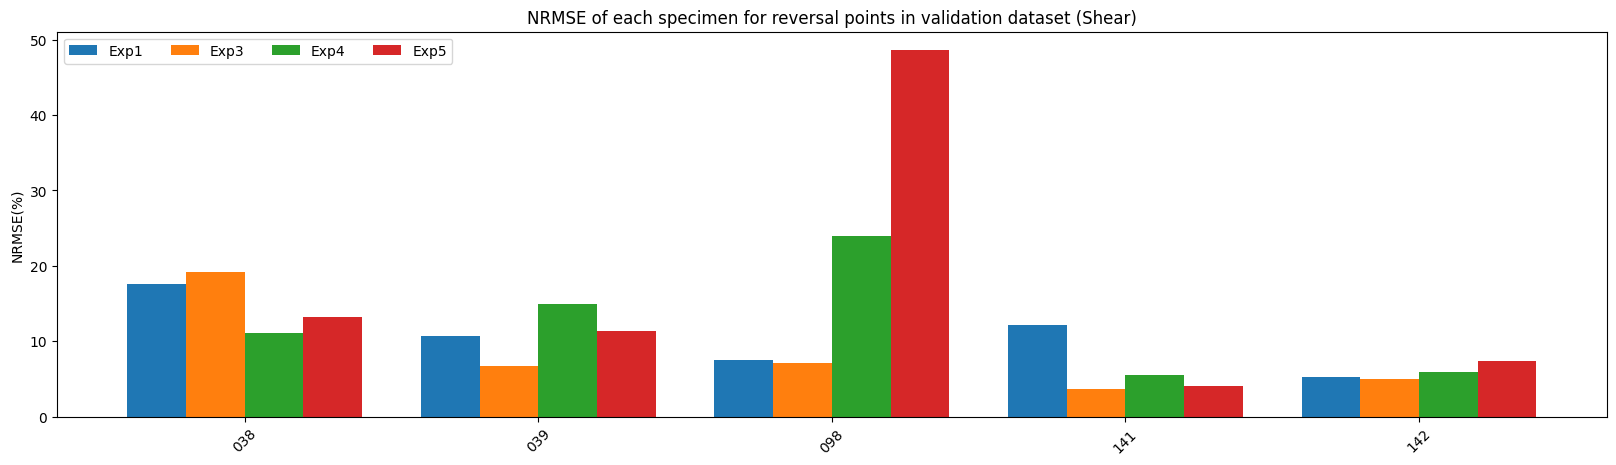

In [4]:
x = np.arange(len(id_list))  # the label locations
width = 0.2 # the width of the bars
multiplier = -0.5

fig, ax = plt.subplots(figsize=(20, 5))
for exp in history_list.keys():
    offset = width * multiplier
    rects = ax.bar(x + offset, [i * 100 for i in history_list[exp]["peak_nrmse"]], width, label=exp)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('NRMSE(%)')
ax.set_title(f'NRMSE of each specimen for reversal points in validation dataset ({failure_mode})')
ax.set_xticks(x + width, id_list)
ax.legend(loc='upper left', ncols=4)
ax.tick_params(axis='x', rotation=45)
plt.savefig(f"./{failure_mode}_nrmse.pdf", transparent=False, bbox_inches="tight")

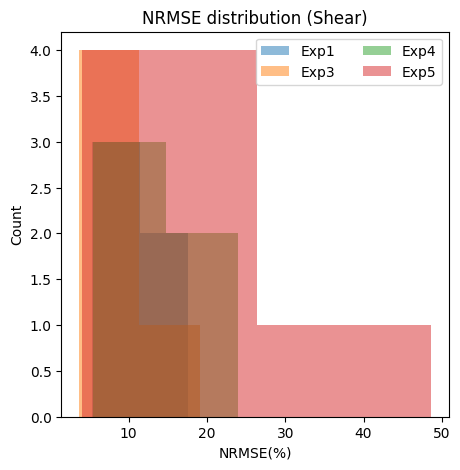

In [7]:
# Draw histogram of NRMSE
fig, ax = plt.subplots(figsize=(5, 5))
for exp in history_list.keys():
    ax.hist([i * 100 for i in history_list[exp]["peak_nrmse"]], bins=2, alpha=0.5, label=exp)
ax.set_ylabel('Count')
ax.set_xlabel('NRMSE(%)')
ax.set_title(f'NRMSE distribution ({failure_mode})')
ax.legend(loc='upper right', ncols=2)
plt.savefig(f"./{failure_mode}_nrmse_hist.pdf", transparent=False, bbox_inches="tight")